# View 2: Latent Space Projections (UMAP)
Visualizes AkidaNet penultimate representation drift under corruption and where the CNN and Akida model disagree.

In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap

In [16]:
df = pd.read_parquet("results_card/predictions_with_embeddings.parquet")
os.makedirs("../figures/phase1_human", exist_ok=True)

#df_sample = df.groupby(["corruption", "severity"]).sample(n=200, random_state=42) # subsample, 30k images is too heavy for UMAP memory limits
features = np.vstack(df["embedding"].values)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embeddings_2d = reducer.fit_transform(features)

df["umap_x"] = embeddings_2d[:, 0]
df["umap_y"] = embeddings_2d[:, 1]

/home/user/.venvs/ai-vis-2026/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Plot AkidaNet Latent Drift

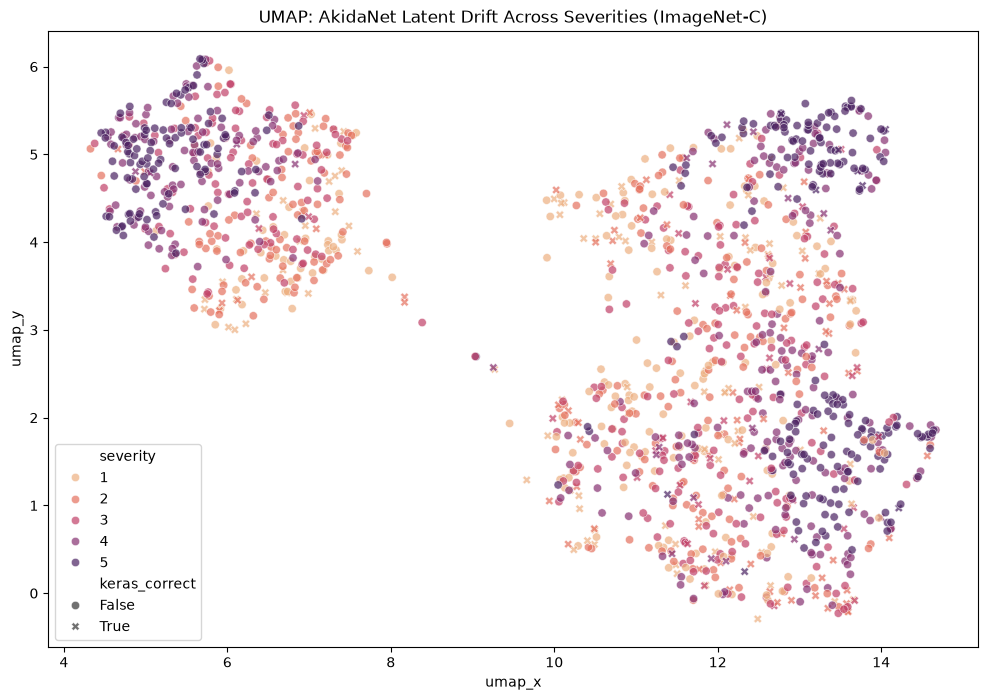

In [17]:
plt.figure(figsize=(12, 8))

sns.scatterplot(data=df, x="umap_x", y="umap_y",hue="severity", style="keras_correct", alpha=0.7, palette="flare")

plt.title("UMAP: AkidaNet Latent Drift Across Severities (ImageNet-C)")

plt.savefig("../figures/phase1_human/akidanet_umap_drift.png", bbox_inches="tight")#store image
plt.show()